Realizado por:
Andrea Bonilla
July Aparicio
Ioshua Castillejos

# Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes
## A - Objetivo

Desarrollar un método basado en redes neuronales recurrentes que permita clasificar con precisión las reseñas de películas en IMDb en una de las dos
categorías: positiva o negativa

## B - Conjunto de datos

Los datos corresponden a un dataset de reseñas de películas en IMDb,
disponibles en el siguiente enlace. El dataset contiene miles de reseñas
etiquetadas con su correspondiente rating y etiqueta de sentimiento (positivo o
negativo)

## C - Actividades por realizar
1. Preprocesamiento de las reseñas: Construir un pipeline que permita limpiar y
tokenizar las reseñas de texto, convirtiéndolas en secuencias numéricas
utilizando embeddings
2. Desarrollo de la arquitectura de red neuronal recurrente: Implementar una
RNN (por ejemplo, LSTM o GRU) para la clasificación de las reseñas en dos
categorías. La arquitectura de la red es de libre elección, pero se sugiere incluir
capas de embedding, capas recurrentes y una capa densa de salida con
activación sigmoide. Justificar la elección de cada capa del modelo.
3. Entrenamiento y evaluación del modelo: Dividir el dataset en conjuntos de
entrenamiento, validación y prueba. Entrenar el modelo utilizando el conjunto de
entrenamiento y evaluar su rendimiento con el conjunto de prueba, reportando
métricas de precisión, recall y F1-score.

### 1. Librerias


In [12]:
#Importamos las librerias requeridas
#Importamos pytorch con los modulos para construir redes neuronales
import pandas as pd               # Librería para manejo de dataframes
import numpy as np                # Librería para trabajar con datos matriciales
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score   # Importar métricas de validación
from sklearn.preprocessing import StandardScaler

from time import time
from gensim.models import Word2Vec
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()

import copy

# Usar el almacén de certificados del sistema operativo (evita CERTIFICATE_VERIFY_FAILED
# en redes con proxy corporativo, sobre todo con Python 3.13)
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

# Descargar solo los recursos que no estén ya instalados
for recurso, ruta in [('punkt', 'tokenizers/punkt'),
                      ('punkt_tab', 'tokenizers/punkt_tab'),
                      ('stopwords', 'corpora/stopwords')]:
    try:
        nltk.data.find(ruta)
    except LookupError:
        nltk.download(recurso, quiet=True)

#Inicializamos las semillas
torch.manual_seed(42)
np.random.seed(42)

#Se define el uso de GPU y cuda para el procesamiento de las redes convolucionales
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


### 2. Importar los datos

In [13]:
GHI = pd.read_csv('movie.csv')
GHI.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    40000 non-null  object
 1   label   40000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 625.1+ KB


### 3. Exploración de datos

In [14]:
GHI.head()

,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


In [15]:
GHI['label'].value_counts()

label
0    20019
1    19981
Name: count, dtype: int64

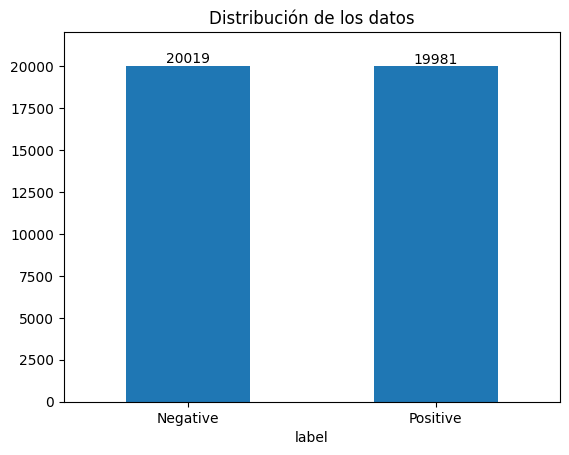

In [16]:
ax = GHI.groupby('label').count().plot(kind='bar', title='Distribución de los datos',
                                       legend=False)
ax.set_xticklabels(['Negative', 'Positive'], rotation=0)

for container in ax.containers:
    ax.bar_label(container)

ax.margins(y=0.1)  # deja espacio arriba para que no se corte el número


In [17]:
longitudes = GHI['text'].str.split().str.len()
print(f"Textos muy cortos (<5 palabras): {(longitudes < 5).sum()}")
print(f"Textos muy largos (>1000 palabras): {(longitudes > 1000).sum()}")
print(f"Filas con registros nulos: {GHI['text'].isnull().sum()}")
print(f"Filas invalidas: {GHI['text'].isna().sum()}")
print(f"Filas duplicadas: {GHI['text'].duplicated().sum()}")

Textos muy cortos (<5 palabras): 1
Textos muy largos (>1000 palabras): 60
Filas con registros nulos: 0
Filas invalidas: 0
Filas duplicadas: 277


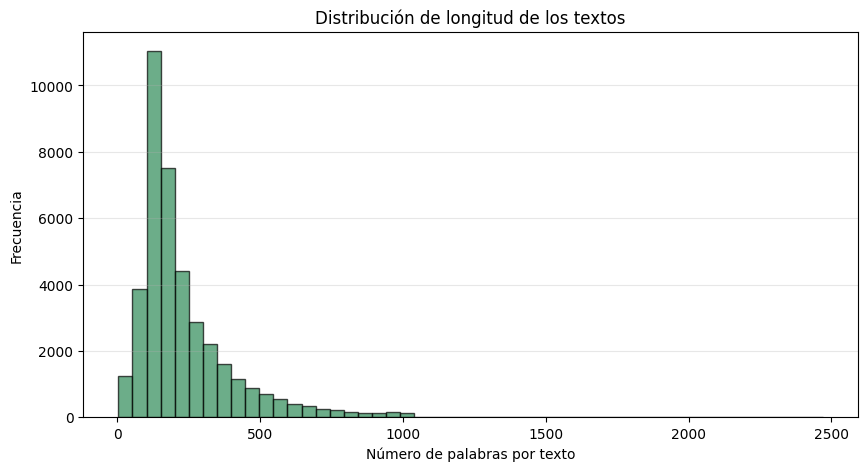

count    40000.000000
mean       231.339250
std        171.194123
min          4.000000
25%        126.000000
50%        173.000000
75%        282.000000
max       2470.000000
Name: text, dtype: float64


In [18]:
longitudes = GHI['text'].str.split().str.len()

plt.figure(figsize=(10,5))
plt.hist(longitudes, bins=50, color='seagreen', edgecolor='black', alpha=0.7)
plt.xlabel('Número de palabras por texto')
plt.ylabel('Frecuencia')
plt.title('Distribución de longitud de los textos')
plt.grid(axis='y', alpha=0.3)
plt.show()

print(longitudes.describe())

Hallazgos de la exploración de datos.

Observamos una distribución normal de los datos muestra que el total de reseñas esta distribuido para cada etiqueta (Positiva y Negativa). Se detectaron 277 registros duplicados, por lo que se hara una limpieza de estos. Se observa que la media de los textos esta en 231 palabras, y en los extremos de nuestro rango tenemos textos desde 4 palabras hasta 2470 palabras.

### 4. Separación de datos

In [19]:
# Quitar duplicados antes de dividir, para que una reseña no quede en entrenamiento y prueba a la vez
GHI = GHI.drop_duplicates(subset='text').reset_index(drop=True)
print(f"Registros tras eliminar duplicados: {len(GHI)}")

SEED = 42

# 70% train, 15% validación, 15% prueba
train_GHI, resto = train_test_split(GHI, test_size=0.30, stratify=GHI["label"], random_state=SEED)
val_GHI, test_GHI = train_test_split(resto, test_size=0.50, stratify=resto["label"], random_state=SEED)
print(f"Datos entrenamiento: {len(train_GHI)}\nDatos validacion: {len(val_GHI)} \nDatos prueba: {len(test_GHI)}")

Registros tras eliminar duplicados: 39723
Datos entrenamiento: 27806
Datos validacion: 5958 
Datos prueba: 5959


### 5. Función de limpieza de textos

In [21]:
import re
import html

# Stopwords de NLTK, pero conservando negaciones e intensificadores (cambian el sentimiento)
conservar = {'no', 'nor', 'not', 'but', 'very', 'too', 'against', 'only'}
stop_words = set(stopwords.words('english')) - conservar

def limpiar_texto(texto, quitar_stopwords=True):
    texto = html.unescape(texto)                       # &amp; -> &
    texto = re.sub(r'<[^>]+>', ' ', texto)             # etiquetas HTML (<br />)
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)    # URLs
    texto = texto.lower().replace('\u2019', "'")       # minúsculas y apóstrofo tipográfico
    texto = re.sub(r"\bwon't\b", 'will not', texto)    # negaciones irregulares
    texto = re.sub(r"\bcan't\b", 'can not', texto)
    texto = re.sub(r"n't\b", ' not', texto)            # didn't -> did not
    texto = re.sub(r"'(s|re|ve|d|ll|m)\b", ' ', texto) # otras contracciones
    texto = re.sub(r'[^a-z\s]', ' ', texto)            # solo letras
    palabras_limpias = texto.split()
    if quitar_stopwords:
        palabras_limpias = [t for t in palabras_limpias if t not in stop_words and len(t) > 1]
        #palabras_limpias = [stemmer.stem(t) for t in palabras_limpias]
    #Regresa una cadena de textos separados en palabras_limpias.
    return palabras_limpias

print(limpiar_texto("I didn't like it.<br /><br />It WASN'T good &amp; I can't recommend it!!"))
# ['not', 'like', 'not', 'good', 'not', 'recommend']

# Se aplica la misma limpieza a cada conjunto (es por reseña, así que no hay fuga de información)
for conjunto in (train_GHI, val_GHI, test_GHI):
    conjunto['palabras_limpias'] = conjunto['text'].apply(limpiar_texto)

['not', 'like', 'not', 'good', 'not', 'recommend']


### 6. Embeddings



In [23]:
from gensim.models import Word2Vec

Embedding_dimensions = 100

w2v = Word2Vec(
    sentences=train_GHI["palabras_limpias"].tolist(),
    vector_size=Embedding_dimensions,
    window=5,
    min_count=1,
    workers=4,
    seed=42,
)

print(f"Palabras en el modelo Word2Vec: {len(w2v.wv):,}")
print("Similares a 'great':", w2v.wv.most_similar('great', topn=5))

Palabras en el modelo Word2Vec: 78,514
Similares a 'great': [('fine', 0.7759199142456055), ('wonderful', 0.7643249034881592), ('excellent', 0.7500244379043579), ('fantastic', 0.749468982219696), ('amazing', 0.7183400392532349)]


### 7. Matriz con embeddings

In [ ]:
from collections import Counter

MAX_VOCAB = 20000
MAX_LEN = 300
EMB_DIM = 100

# Vocabulario construido solo con train (evita fuga de información). 0 = <PAD>, 1 = <UNK>
contador = Counter(t for toks in train_GHI["palabras_limpias"] for t in toks)
palabras = [p for p, _ in contador.most_common(MAX_VOCAB - 2)]
word2idx = {p: i + 2 for i, p in enumerate(palabras)}
VOCAB_SIZE = len(word2idx) + 2

def codificar(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN]
    # padding al inicio para que el último paso de la LSTM sea una palabra real
    return [0] * (MAX_LEN - len(ids)) + ids

In [28]:
# Matriz de embeddings inicializada con los vectores de Word2Vec, alineada con word2idx
matriz_emb = np.random.normal(0, 0.1, (VOCAB_SIZE, EMB_DIM)).astype("float32")
matriz_emb[0] = 0.0   # <PAD> en ceros
encontradas = 0
for palabra, idx in word2idx.items():
    if palabra in w2v.wv:
        matriz_emb[idx] = w2v.wv[palabra]
        encontradas += 1
print(f"Palabras con vector Word2Vec: {encontradas:,} / {len(word2idx):,}")


Palabras con vector Word2Vec: 19,998 / 19,998


### 8. Craeación de tensores

In [27]:
#Creación de los tensores, para X asignamos la columna palabras_limpias
#Para el tensor y, asignamos las etiquetas 0 y 1 
def a_tensores(frame):
    X = torch.tensor([codificar(t) for t in frame["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(frame["label"].values, dtype=torch.float32)
    return X, y

X_train, y_train = a_tensores(train_GHI)
X_val, y_val = a_tensores(val_GHI)
X_test, y_test = a_tensores(test_GHI)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256)
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([27806, 300]) torch.Size([5958, 300]) torch.Size([5959, 300])


### 3. Modelo

El modelo empieza con una capa de embedding que se inicializa con los vectores de Word2Vec entrenados con las reseñas de entrenamiento. Se hizo así para que la red no arranque desde cero y ya tenga una idea de qué palabras se parecen entre sí, por ejemplo *great* y *excellent*. Esta capa se dejó entrenable para que los vectores se puedan ajustar a la clasificación de sentimiento. El índice 0 se usa para el padding y queda en ceros.

Después del embedding se agregó un dropout de 0.3, porque con un vocabulario de 20.000 palabras el modelo puede aprenderse palabras específicas de memoria y no generalizar bien.

La parte principal es una LSTM bidireccional de 128 unidades. Se escogió LSTM en lugar de una RNN simple porque las reseñas son largas (se cortaron en 300 palabras) y la RNN simple tiende a olvidar lo que leyó al principio por el desvanecimiento del gradiente. Se usó bidireccional porque el sentido de una palabra a veces depende de lo que viene después, como en "not bad at all". Los estados finales de las dos direcciones se concatenan y quedan en un vector de 256.

A la salida de la LSTM se puso otro dropout, esta vez de 0.4, y luego una capa densa de 64 neuronas con ReLU que combina la información antes de clasificar.

La última capa tiene una sola neurona y da la probabilidad de que la reseña sea positiva; si es 0.5 o más se toma como positiva. La sigmoide no va dentro del modelo sino en la función de pérdida, `BCEWithLogitsLoss`, porque así el cálculo es más estable. Al momento de predecir se aplica con `torch.sigmoid`.

Para entrenar se usó Adam con tasa de aprendizaje de 0.001 y se limitó el gradiente a 1.0, ya que en las LSTM los gradientes a veces se disparan y el entrenamiento se vuelve inestable.


In [29]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim=100, hidden_dim=128, num_layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.emb_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        emb = self.emb_dropout(self.embedding(x))   # (batch, MAX_LEN, emb_dim)
        _, (h_n, _) = self.lstm(emb)                # h_n: (num_layers, batch, hidden_dim)
        h = self.dropout(h_n[-1])                   # último estado oculto de la última capa
        return self.sigmoid(self.fc(h)).squeeze(1)  # probabilidad de clase positiva

modelo = SentimentLSTM(VOCAB_SIZE, EMB_DIM).to(device)
modelo.embedding.weight.data.copy_(torch.tensor(matriz_emb))
modelo.embedding.weight.requires_grad = True
criterio = nn.BCELoss()
optimizador = optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)   # weight_decay: regularización L2
# Si la pérdida de validación no mejora en 1 época, la tasa de aprendizaje se reduce a la mitad
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="min", factor=0.5, patience=1)

print(modelo)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

SentimentLSTM(
  (embedding): Embedding(20000, 100, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parámetros entrenables: 2,249,985


### 4. Entrenamiento con validación

En cada época el modelo se entrena con `train_loader` y se evalúa con `val_loader`. Se guarda el modelo con **menor pérdida de validación** y se detiene el entrenamiento si esta no mejora durante 5 épocas seguidas (*early stopping*), con un máximo de 50 épocas. Además, cuando la pérdida de validación deja de mejorar, la tasa de aprendizaje se reduce a la mitad (`ReduceLROnPlateau`). El conjunto de prueba no se usa en esta etapa.

In [32]:
def ejecutar_epoca(loader, entrenar):
    """Recorre un loader una vez. Si entrenar=True actualiza los pesos. Devuelve (pérdida, accuracy)."""
    modelo.train() if entrenar else modelo.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo(xb)
            perdida = criterio(prob, yb)
            if entrenar:
                optimizador.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS = 50      # máximo de épocas; el early stopping corta antes si ya no mejora
PACIENCIA = 10    # épocas sin mejorar en validación antes de detener el entrenamiento

historial = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss = float("inf")
mejor_estado = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS + 1):
    tr_loss, tr_acc = ejecutar_epoca(train_loader, entrenar=True)
    va_loss, va_acc = ejecutar_epoca(val_loader, entrenar=False)
    scheduler.step(va_loss)   # ajusta la tasa de aprendizaje según la pérdida de validación
    for k, v in zip(historial, (tr_loss, va_loss, tr_acc, va_acc)):
        historial[k].append(v)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss:
        mejor_val_loss = va_loss
        mejor_estado = copy.deepcopy(modelo.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print(f"Early stopping: la pérdida de validación no mejora hace {PACIENCIA} épocas")
            break

modelo.load_state_dict(mejor_estado)   # se queda con el mejor modelo según validación
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss:.4f}")

Época  1 | train loss 0.1686 acc 0.9384 | val loss 0.2821 acc 0.9015 | lr 1.3e-04
Época  2 | train loss 0.1536 acc 0.9446 | val loss 0.2760 acc 0.8998 | lr 1.3e-04
Época  3 | train loss 0.1474 acc 0.9458 | val loss 0.2931 acc 0.9006 | lr 6.3e-05
Época  4 | train loss 0.1376 acc 0.9501 | val loss 0.2781 acc 0.9005 | lr 6.3e-05
Época  5 | train loss 0.1344 acc 0.9512 | val loss 0.2860 acc 0.8996 | lr 3.1e-05
Época  6 | train loss 0.1296 acc 0.9539 | val loss 0.2896 acc 0.8998 | lr 3.1e-05
Época  7 | train loss 0.1302 acc 0.9529 | val loss 0.2874 acc 0.9000 | lr 1.6e-05
Época  8 | train loss 0.1267 acc 0.9544 | val loss 0.2878 acc 0.8996 | lr 1.6e-05
Época  9 | train loss 0.1257 acc 0.9550 | val loss 0.2907 acc 0.8998 | lr 7.8e-06
Época 10 | train loss 0.1234 acc 0.9559 | val loss 0.2951 acc 0.9003 | lr 7.8e-06
Época 11 | train loss 0.1259 acc 0.9546 | val loss 0.2925 acc 0.9010 | lr 3.9e-06
Época 12 | train loss 0.1251 acc 0.9552 | val loss 0.2933 acc 0.8998 | lr 3.9e-06
Early stopping: 

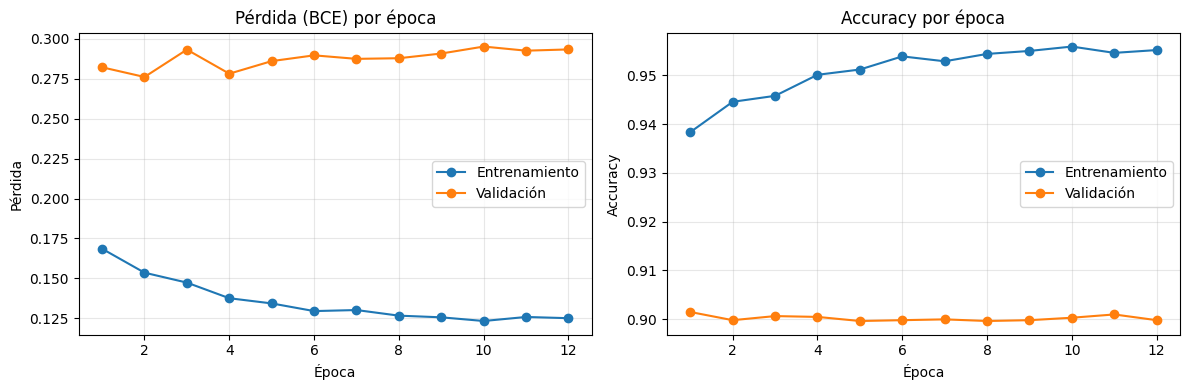

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial["train_loss"]) + 1)

axes[0].plot(epocas_x, historial["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

### 5. Evaluación en el conjunto de prueba

Se evalúa una sola vez el mejor modelo (según validación) con el 30 % de prueba, que no se usó para entrenar ni para elegir el modelo. Se reportan precisión, recall y F1-score por clase, junto con la matriz de confusión.

Accuracy : 0.8965
Precisión: 0.9017
Recall   : 0.8905
F1-score : 0.8960

              precision    recall  f1-score   support

    Negativa     0.8914    0.9025    0.8969      2973
    Positiva     0.9017    0.8905    0.8960      2986

    accuracy                         0.8965      5959
   macro avg     0.8965    0.8965    0.8965      5959
weighted avg     0.8965    0.8965    0.8965      5959



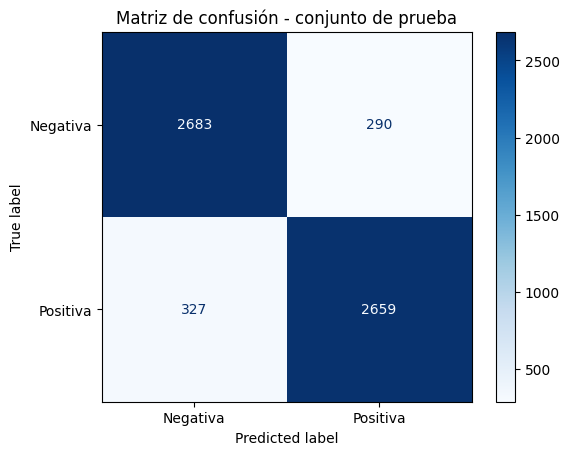

In [34]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

modelo.eval()
probs, reales = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        probs.append(modelo(xb.to(device)).cpu())
        reales.append(yb)
probs = torch.cat(probs).numpy()
y_real = torch.cat(reales).numpy().astype(int)
y_pred = (probs >= 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_real, y_pred):.4f}")
print(f"Precisión: {precision_score(y_real, y_pred):.4f}")
print(f"Recall   : {recall_score(y_real, y_pred):.4f}")
print(f"F1-score : {f1_score(y_real, y_pred):.4f}\n")
print(classification_report(y_real, y_pred, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - conjunto de prueba")
plt.show()